# 04c · Extensión Fase 3: Híbrido ConvNeXt-Tiny + ViT-B/16 con atención cruzada

Este notebook implementa y entrena el **quinto clasificador** de la comparación controlada:
un modelo híbrido creado a medida (**`hybrid_convnext_vit`**) que fusiona:

- **Rama local:** `ConvNeXt-Tiny` (`IMAGENET1K_V1`, salida espacial `16×16×768`).
- **Rama global:** `ViT-B/16` (`IMAGENET1K_V1` con interpolación bicúbica `224→512`, `32×32` tokens espaciales de dimensión `768`).
- **Fusión (`CrossFusion`):** agrupación a rejilla común `8×8`, proyección a `256` dimensiones y
  atención cruzada bidireccional de `4` cabezas entre ambas ramas (sin compilar kernels CUDA externos).

Conserva exactamente el protocolo controlado (`seed=20261019`, 3 clases, `512×512`, hasta 12 épocas,
2 de warmup, paciencia 4, lote efectivo 32, FP32, `head_lr=3e-4`, `backbone_lr=5e-6`).
**El conjunto de prueba (`test`) y externos permanecen reservados.**

## Paso 1 — Montar Drive, verificar paquete ZIP y preparar dataset

Coloque `tbx11k_hibrido_convnext_vit_colab.zip` en `MyDrive/Proyecto_Tuberculosis/`
(junto a `TBX11K.zip` o `TBX11K/`). No sobrescribe los experimentos anteriores.

In [1]:
import hashlib, importlib.metadata as metadata, json, stat, subprocess, sys, zipfile
from pathlib import Path, PurePosixPath
from google.colab import drive
drive.mount('/content/drive')
DRIVE_BASE = Path('/content/drive/MyDrive/Proyecto_Tuberculosis')
ARCHIVE = DRIVE_BASE / 'tbx11k_hibrido_convnext_vit_colab.zip'
EXPECTED_PACKAGE_SHA256 = '43ffeda8a1eaf2c58c5699b55ebe4df745f2eb35f887bd45780a07f6acb1beff'
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()
if file_sha256(ARCHIVE) != EXPECTED_PACKAGE_SHA256:
    raise ValueError('ZIP diferente de esta versión del notebook. Use ambos archivos de la misma entrega.')
PROJECT_ROOT = Path('/content/tbx11k_hybrid_vit/project')
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ARCHIVE) as archive:
    names = archive.namelist()
    if len(names) != len(set(names)):
        raise ValueError('ZIP con nombres duplicados.')
    for item in archive.infolist():
        rel = PurePosixPath(item.filename)
        target = (PROJECT_ROOT / item.filename).resolve()
        if (rel.is_absolute() or '..' in rel.parts or ':' in item.filename
                or chr(92) in item.filename or stat.S_ISLNK(item.external_attr >> 16)
                or PROJECT_ROOT.resolve() not in target.parents):
            raise ValueError('Ruta ZIP insegura: ' + item.filename)
    checksums = json.loads(archive.read('hybrid_vit_package_checksums.json'))
    if set(names) != set(checksums) | {'hybrid_vit_package_checksums.json'}:
        raise ValueError('Cobertura de checksums incorrecta.')
    for name, expected in checksums.items():
        if hashlib.sha256(archive.read(name)).hexdigest() != expected:
            raise ValueError('Archivo alterado en el paquete: ' + name)
    archive.extractall(PROJECT_ROOT)
for name in list(sys.modules):
    if name in {'tbxdata', 'tbxtrain'} or name.startswith(('tbxdata.', 'tbxtrain.')):
        del sys.modules[name]
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
print('Paquete verificado y extraído en:', PROJECT_ROOT)

Mounted at /content/drive
Paquete verificado y extraído en: /content/tbx11k_hybrid_vit/project


In [2]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Seleccione un runtime GPU de Colab (T4/L4/A100).')
protected = {}
for name in ['torch', 'torchvision', 'torchaudio']:
    try:
        protected[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        pass
constraints = PROJECT_ROOT / 'runtime_constraints.txt'
constraints.write_text(''.join(f'{k}=={v}\n' for k, v in protected.items()))
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '--quiet', '--disable-pip-version-check',
    '-c', str(constraints), '-r', str(PROJECT_ROOT / 'requirements-training.txt'),
])
if any(metadata.version(k) != v for k, v in protected.items()):
    raise RuntimeError('Se alteró torch/torchvision del runtime. Reinicie antes de continuar.')
from tbxdata.colab import stage_dataset
from tbxdata.validate import validate_manifests
from tbxtrain.hybrid_vit_experiment import validate_hybrid_vit_config
source = DRIVE_BASE / 'TBX11K.zip'
if not source.exists():
    source = DRIVE_BASE / 'TBX11K'
DATASET_ROOT = stage_dataset(source, Path('/content/tbx11k_hybrid_vit/data_cache'), True)
integrity = validate_manifests(PROJECT_ROOT, DATASET_ROOT, all_image_hashes=True)
CONFIG_HYB_VIT = validate_hybrid_vit_config(
    json.loads((PROJECT_ROOT / 'configs/hybrid_convnext_vit_controlled.json').read_text()),
    PROJECT_ROOT,
)
print('GPU:', torch.cuda.get_device_name(0), '| torch:', torch.__version__, '| Integridad:', integrity['status'])
print('Hashes verificados:', integrity['all_image_hashes_verified'])
print(json.dumps(CONFIG_HYB_VIT, indent=2, ensure_ascii=False))

GPU: NVIDIA L4 | torch: 2.14.1+cu130 | Integridad: passed
Hashes verificados: 12278
{
  "protocol_id": "phase3_controlled_hybrid_vit_v1",
  "architecture": "hybrid_convnext_vit",
  "display_name": "Híbrido ConvNeXt + ViT-B/16",
  "weights": "ConvNeXt_Tiny_Weights.IMAGENET1K_V1 + ViT_B_16_Weights.IMAGENET1K_V1",
  "seed": 20261019,
  "epochs": 12,
  "warmup_epochs": 2,
  "batch_size": 2,
  "accumulation_steps": 16,
  "num_workers": 2,
  "head_lr": 0.0003,
  "backbone_lr": 5e-06,
  "weight_decay": 0.01,
  "gradient_clip": 1.0,
  "patience": 4,
  "min_delta": 0.001,
  "precision": "fp32",
  "selection_metric": "validation_macro_f1",
  "initialization": "ImageNet oficial por rama (ConvNeXt-Tiny + ViT-B/16 con interpolación bicúbica 224->512); fusión CrossFusion inicializada desde cero",
  "scope": "Extensión de comparación controlada con una seed; mismos datos, splits, aumentos e hiperparámetros que phase3_controlled_v1"
}


## Paso 2 — Smoke técnico de Híbrido ConvNeXt + ViT-B/16 (`RUN_SMOKES = True`)

Una imagen por clase (`health`, `sick`, `TB`) a 512 px verifica carga oficial de ambas ramas,
fusión `CrossFusion`, forward/backward, actualización de la cabeza y reproducibilidad de `best.pt`.

In [3]:
from tbxtrain.hybrid_vit_experiment import run_hybrid_vit_model
RUN_SMOKES = True
if RUN_SMOKES:
    smoke = run_hybrid_vit_model(PROJECT_ROOT, DATASET_ROOT, DRIVE_BASE, CONFIG_HYB_VIT, smoke=True)
    print('Smoke Híbrido C+ViT:', smoke['status'], '| updates:', smoke['optimizer_updates'])

Corrida: smoke_hybrid_convnext_vit_20261116T031620Z_533f63 
Salidas: /content/drive/MyDrive/Proyecto_Tuberculosis/experiments/smoke_hybrid_convnext_vit_20261116T031620Z_533f63
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 236MB/s] 


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 222MB/s]
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:910.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_eng

  época 1 lote 3/3 loss=1.4931
Época 1: macro-F1=0.1667, TB recall=1.0000; Drive guardado.
Smoke Híbrido C+ViT: completed_smoke | updates: 2


## Paso 3 — Entrenamiento completo controlado y recuperación automática

Guarda `last.pt` e `history.csv` al finalizar cada época en Drive. Si la sesión se
interrumpe, vuelva a ejecutar desde el Paso 1 (puede poner `RUN_SMOKES = False`) y esta
celda retomará automáticamente desde `results/hybrid_vit_suite/`.

In [4]:
marker = DRIVE_BASE / 'results/hybrid_vit_suite' / CONFIG_HYB_VIT['protocol_id'] / 'hybrid_convnext_vit.json'
resume = None
HYBRID_VIT_RUN_ID = None
if marker.exists():
    prior = json.loads(marker.read_text())
    prior_id = prior['run_id']
    summary_path = DRIVE_BASE / 'experiments' / prior_id / 'summary.json'
    if summary_path.exists():
        prior_summary = json.loads(summary_path.read_text())
        if prior_summary['status'] == 'completed_controlled':
            if prior_summary['protocol'] != CONFIG_HYB_VIT:
                raise RuntimeError('El protocolo cambió. Defina otro protocol_id para una nueva tanda.')
            HYBRID_VIT_RUN_ID = prior_id
            print('Corrida recuperada sin reentrenar:', HYBRID_VIT_RUN_ID)
    if HYBRID_VIT_RUN_ID is None and (DRIVE_BASE / 'checkpoints' / prior_id / 'last.pt').exists():
        resume = prior_id
if HYBRID_VIT_RUN_ID is None:
    summary = run_hybrid_vit_model(
        PROJECT_ROOT, DATASET_ROOT, DRIVE_BASE, CONFIG_HYB_VIT, resume_run=resume, smoke=False,
    )
    HYBRID_VIT_RUN_ID = summary['run_id']
print('Corrida Híbrido C+ViT completa:', HYBRID_VIT_RUN_ID)

Corrida: phase3_hybrid_convnext_vit_20261116T031647Z_376827 
Salidas: /content/drive/MyDrive/Proyecto_Tuberculosis/experiments/phase3_hybrid_convnext_vit_20261116T031647Z_376827
  época 1 lote 200/2896 loss=1.4433
  época 1 lote 400/2896 loss=1.0687
  época 1 lote 600/2896 loss=0.8490
  época 1 lote 800/2896 loss=0.7465
  época 1 lote 1000/2896 loss=0.6549
  época 1 lote 1200/2896 loss=0.5879
  época 1 lote 1400/2896 loss=0.5377
  época 1 lote 1600/2896 loss=0.4926
  época 1 lote 1800/2896 loss=0.4637
  época 1 lote 2000/2896 loss=0.4413
  época 1 lote 2200/2896 loss=0.4249
  época 1 lote 2400/2896 loss=0.4073
  época 1 lote 2600/2896 loss=0.3968
  época 1 lote 2800/2896 loss=0.3789
  época 1 lote 2896/2896 loss=0.3727
Época 1: macro-F1=0.9289, TB recall=0.9333; Drive guardado.
  época 2 lote 200/2896 loss=0.2045
  época 2 lote 400/2896 loss=0.2101
  época 2 lote 600/2896 loss=0.2245
  época 2 lote 800/2896 loss=0.2141
  época 2 lote 1000/2896 loss=0.1920
  época 2 lote 1200/2896 loss=

## Paso 4 — Exportar figuras, tablas y resumen comparativo de los 5 clasificadores

Genera curvas de entrenamiento, matriz de confusión, ROC OVR, umbrales TB del nuevo híbrido
y la comparación completa de los **5 clasificadores** (`ConvNeXt-Tiny`, `VMamba-Tiny`,
`Híbrido v1`, `ViT-B/16`, `Híbrido ConvNeXt + ViT-B/16`).

**Al terminar, guarde el notebook con Ctrl+S y avise para actualizar `Informe_Avance_Fase_5.docx`.**

=== COMPARACIÓN DE LOS 5 CLASIFICADORES (VALIDATION) ===


,display_name,run_id,completed_epochs,best_epoch,stop_reason,accuracy,macro_f1,TB_recognized,TB_recall,TB_precision,TB_specificity
0,ConvNeXt-Tiny,phase3_convnext_tiny_20261103T023002Z_4a7e2a,12,11,epoch_budget,0.970991,0.942716,94,0.783333,0.969072,0.997324
1,VMamba-Tiny,phase3_vmamba_tiny_20261103T025536Z_4784e4,12,11,epoch_budget,0.968574,0.949672,101,0.841667,0.961905,0.996432
2,Híbrido (ConvNeXt+VMamba),phase3_hybrid_cross_attention_20261103T032205Z...,7,3,early_stopping,0.978243,0.964470,107,0.891667,0.963964,0.996432
3,ViT-B/16,phase3_vit_b_16_20261116T014808Z_2e8a27,12,11,epoch_budget,0.977438,0.964435,110,0.916667,0.940171,0.993756
4,Híbrido ConvNeXt + ViT-B/16,phase3_hybrid_convnext_vit_20261116T031647Z_37...,6,2,early_stopping,0.978243,0.962994,105,0.875000,0.972222,0.997324


=== HISTORIAL POR ÉPOCA · Híbrido ConvNeXt + ViT-B/16 ===


,epoch,train_loss,train_accuracy,optimizer_updates,train_n,stage,validation_loss,validation_accuracy,validation_macro_f1,validation_tb_recall,seconds
0,1,0.3726700276144435,0.8934737569060773,181,5792,head_only,0.13375840842028786,0.9572925060435133,0.9288679896350119,0.9333333333333333,304.930808577
1,2,0.1570141506400639,0.9659875690607734,181,5792,head_only,0.15887529597772523,0.9782433521353747,0.9629935436748385,0.875,307.13177615899997
2,3,0.07821230659842164,0.9834254143646409,181,5792,last_stages,0.21102660672776014,0.9734085414987913,0.9581275427914525,0.8666666666666667,391.640222537
3,4,0.05714903975821757,0.9908494475138122,181,5792,last_stages,0.3652439480558059,0.9734085414987913,0.949499541890274,0.8,391.81551483499993
4,5,0.05944967717863585,0.9880870165745856,181,5792,last_stages,0.4597526241885545,0.9709911361804996,0.9400016614466905,0.75,391.972668463
5,6,0.048387409753925706,0.9906767955801105,181,5792,last_stages,0.5224796498418979,0.9685737308622079,0.9352176863603922,0.7333333333333333,392.14638458599984


=== TABLA DE UMBRALES TB · Híbrido ConvNeXt + ViT-B/16 (VALIDATION) ===


,threshold,tp,fp,fn,tn,sensitivity,specificity,precision,alerts
0,0.05,116,22,4,1099,0.966667,0.980375,0.840580,138
1,0.10,111,15,9,1106,0.925000,0.986619,0.880952,126
2,0.20,109,8,11,1113,0.908333,0.992864,0.931624,117
3,0.30,108,5,12,1116,0.900000,0.995540,0.955752,113
4,0.50,105,2,15,1119,0.875000,0.998216,0.981308,107
5,0.70,98,2,22,1119,0.816667,0.998216,0.980000,100
6,0.90,88,0,32,1121,0.733333,1.000000,1.000000,88


=== CANDIDATO PRINCIPAL POR MACRO-F1 === hybrid_cross_attention


,threshold,tp,fp,fn,tn,sensitivity,specificity,precision,alerts
0,0.05,111,6,9,1115,0.925000,0.994648,0.948718,117
1,0.10,111,5,9,1116,0.925000,0.995540,0.956897,116
2,0.20,109,4,11,1117,0.908333,0.996432,0.964602,113
3,0.30,107,4,13,1117,0.891667,0.996432,0.963964,111
4,0.50,107,4,13,1117,0.891667,0.996432,0.963964,111
5,0.70,106,3,14,1118,0.883333,0.997324,0.972477,109
6,0.90,100,1,20,1120,0.833333,0.999108,0.990099,101


classifier_comparison.png


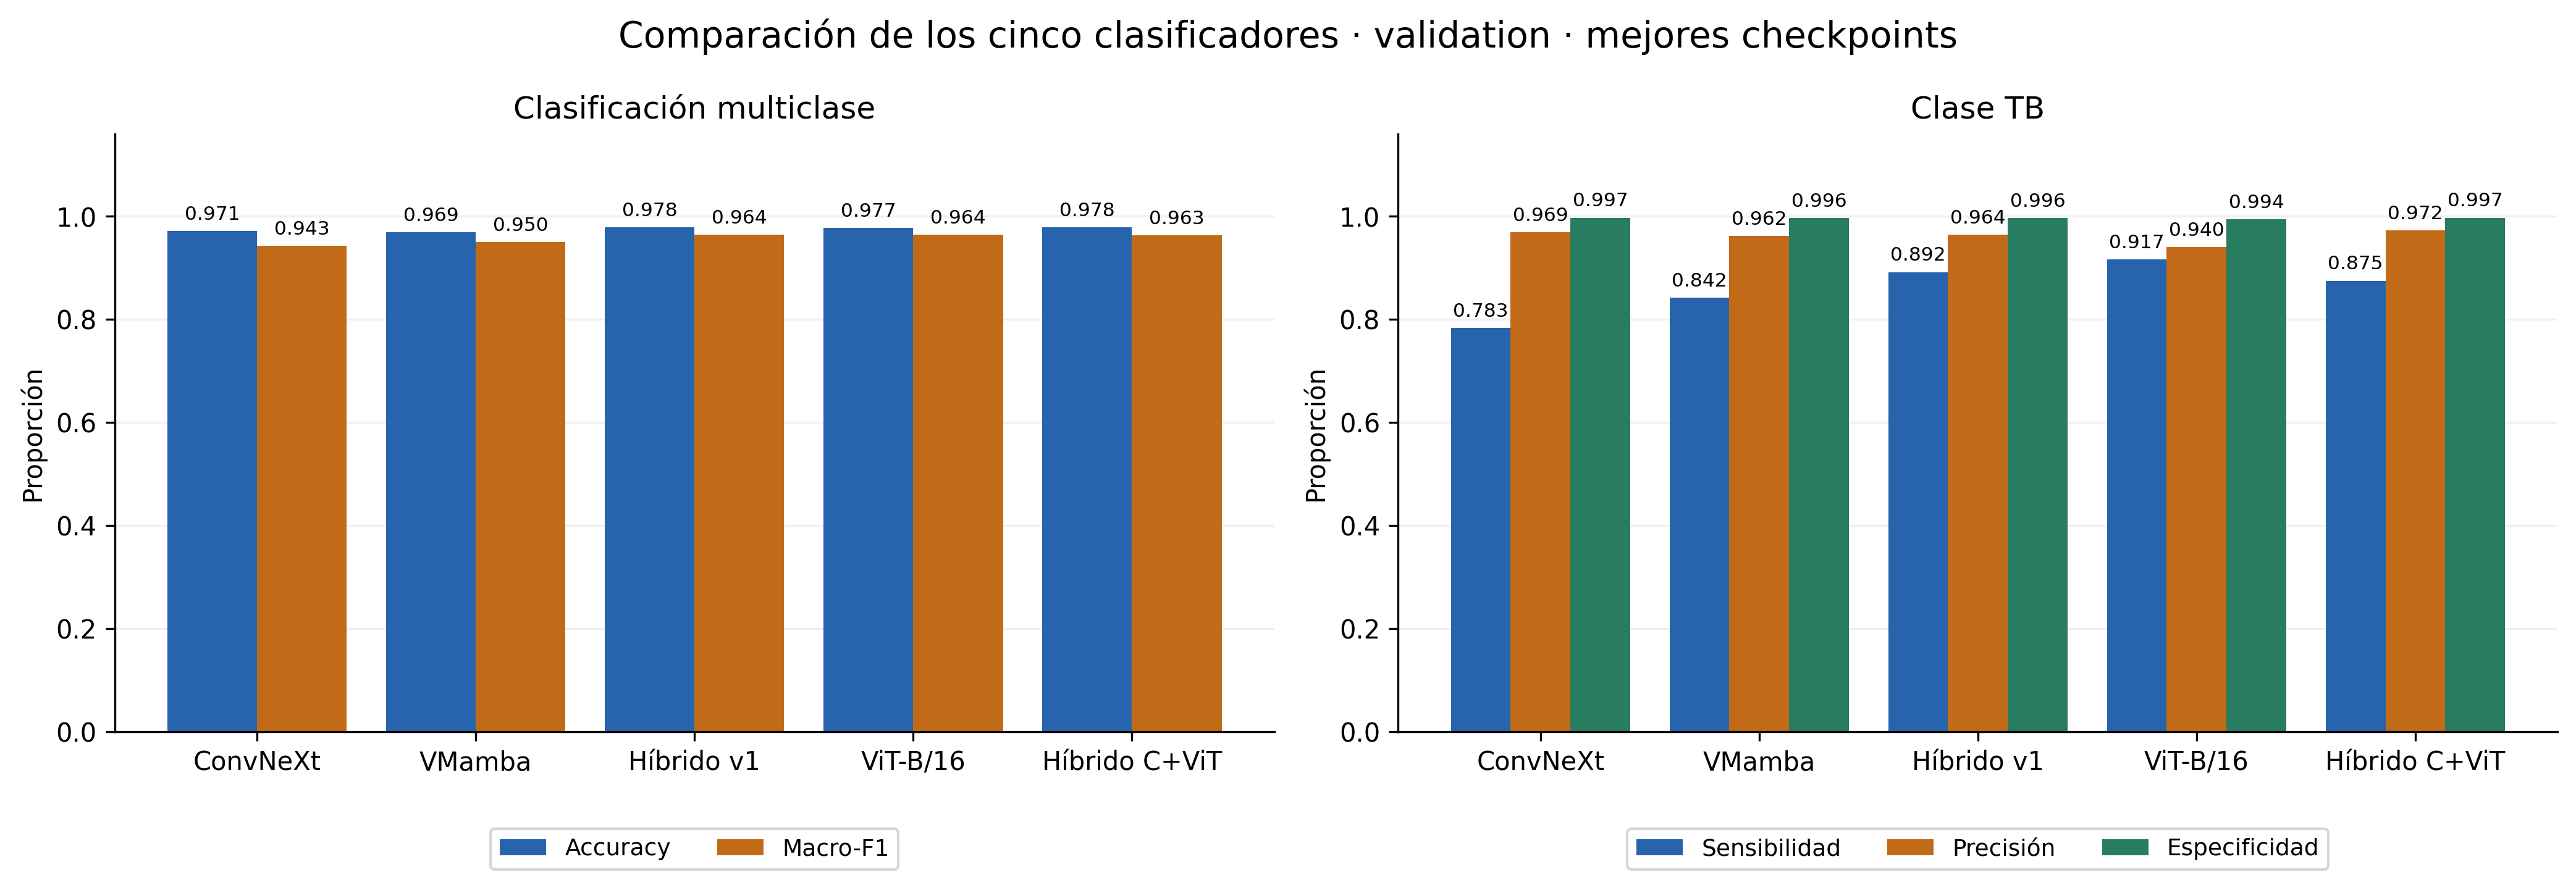

hybrid_convnext_vit_training.png


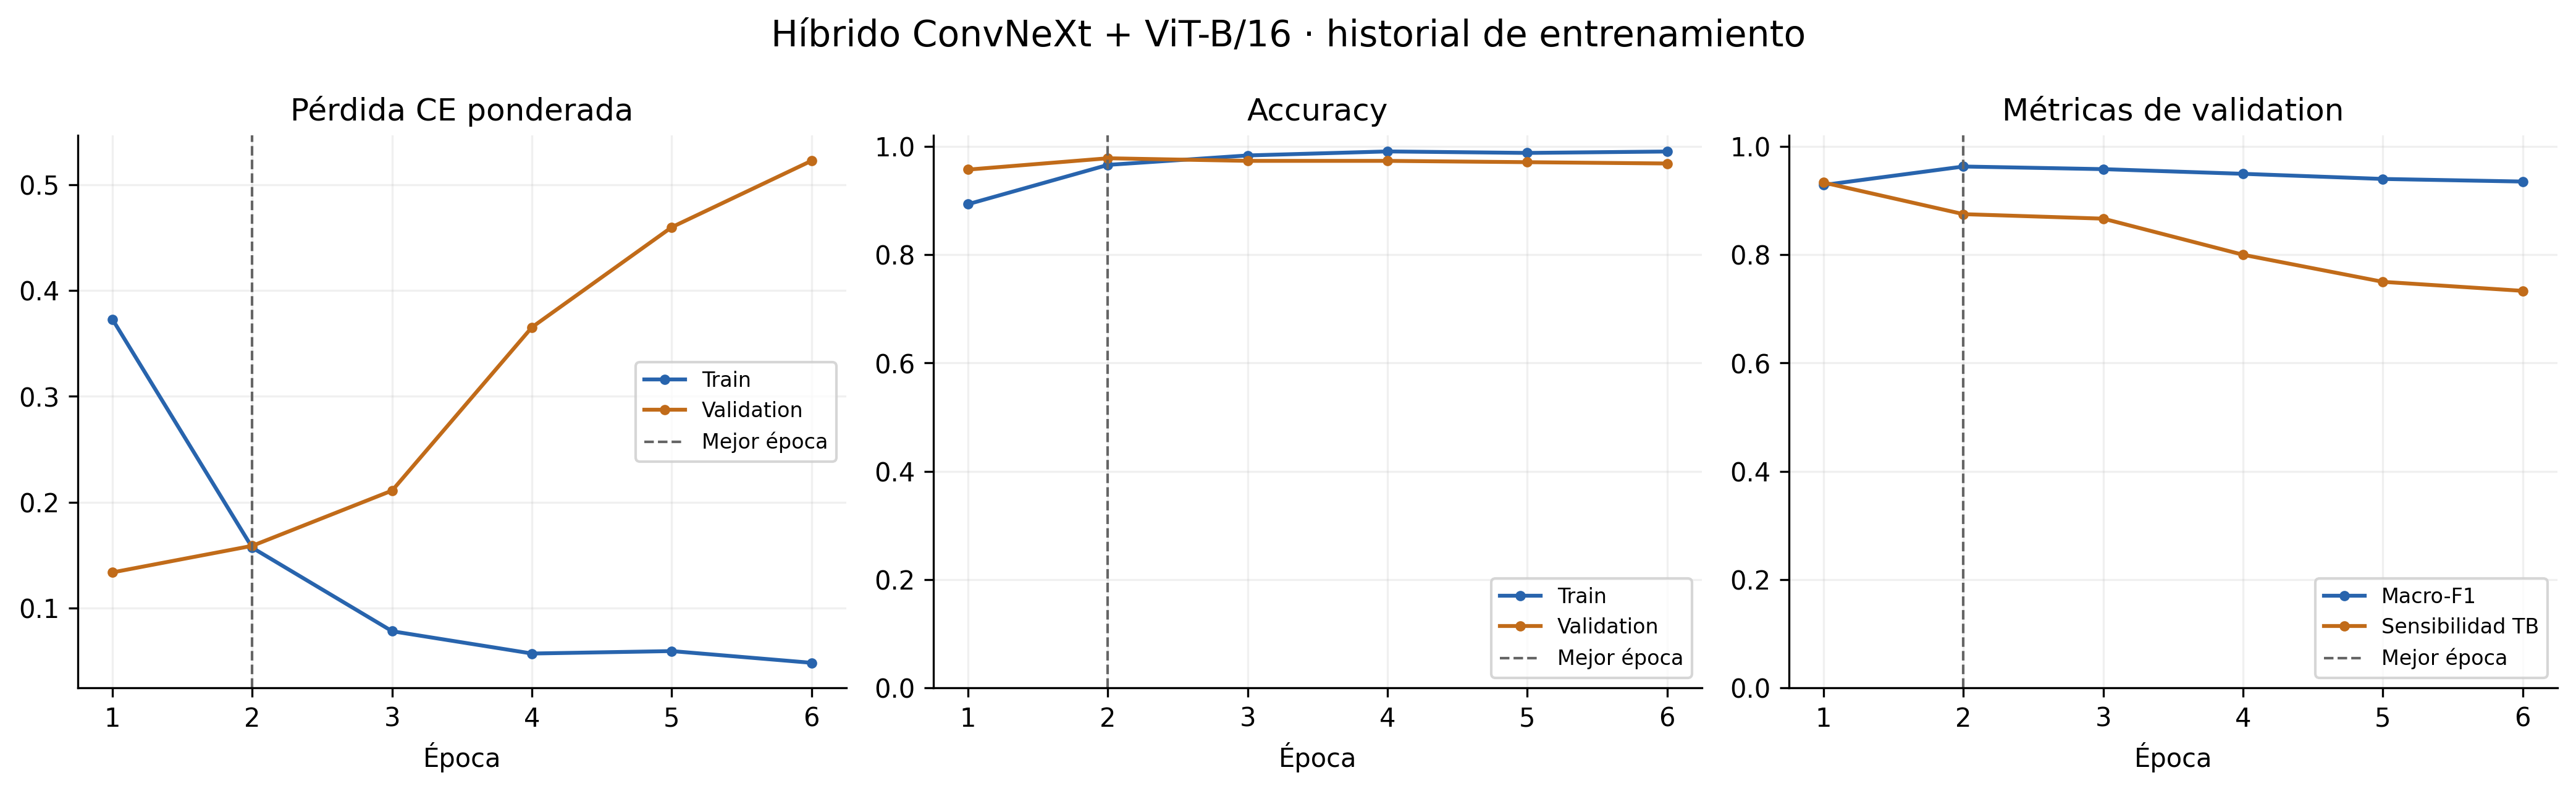

hybrid_convnext_vit_confusion.png


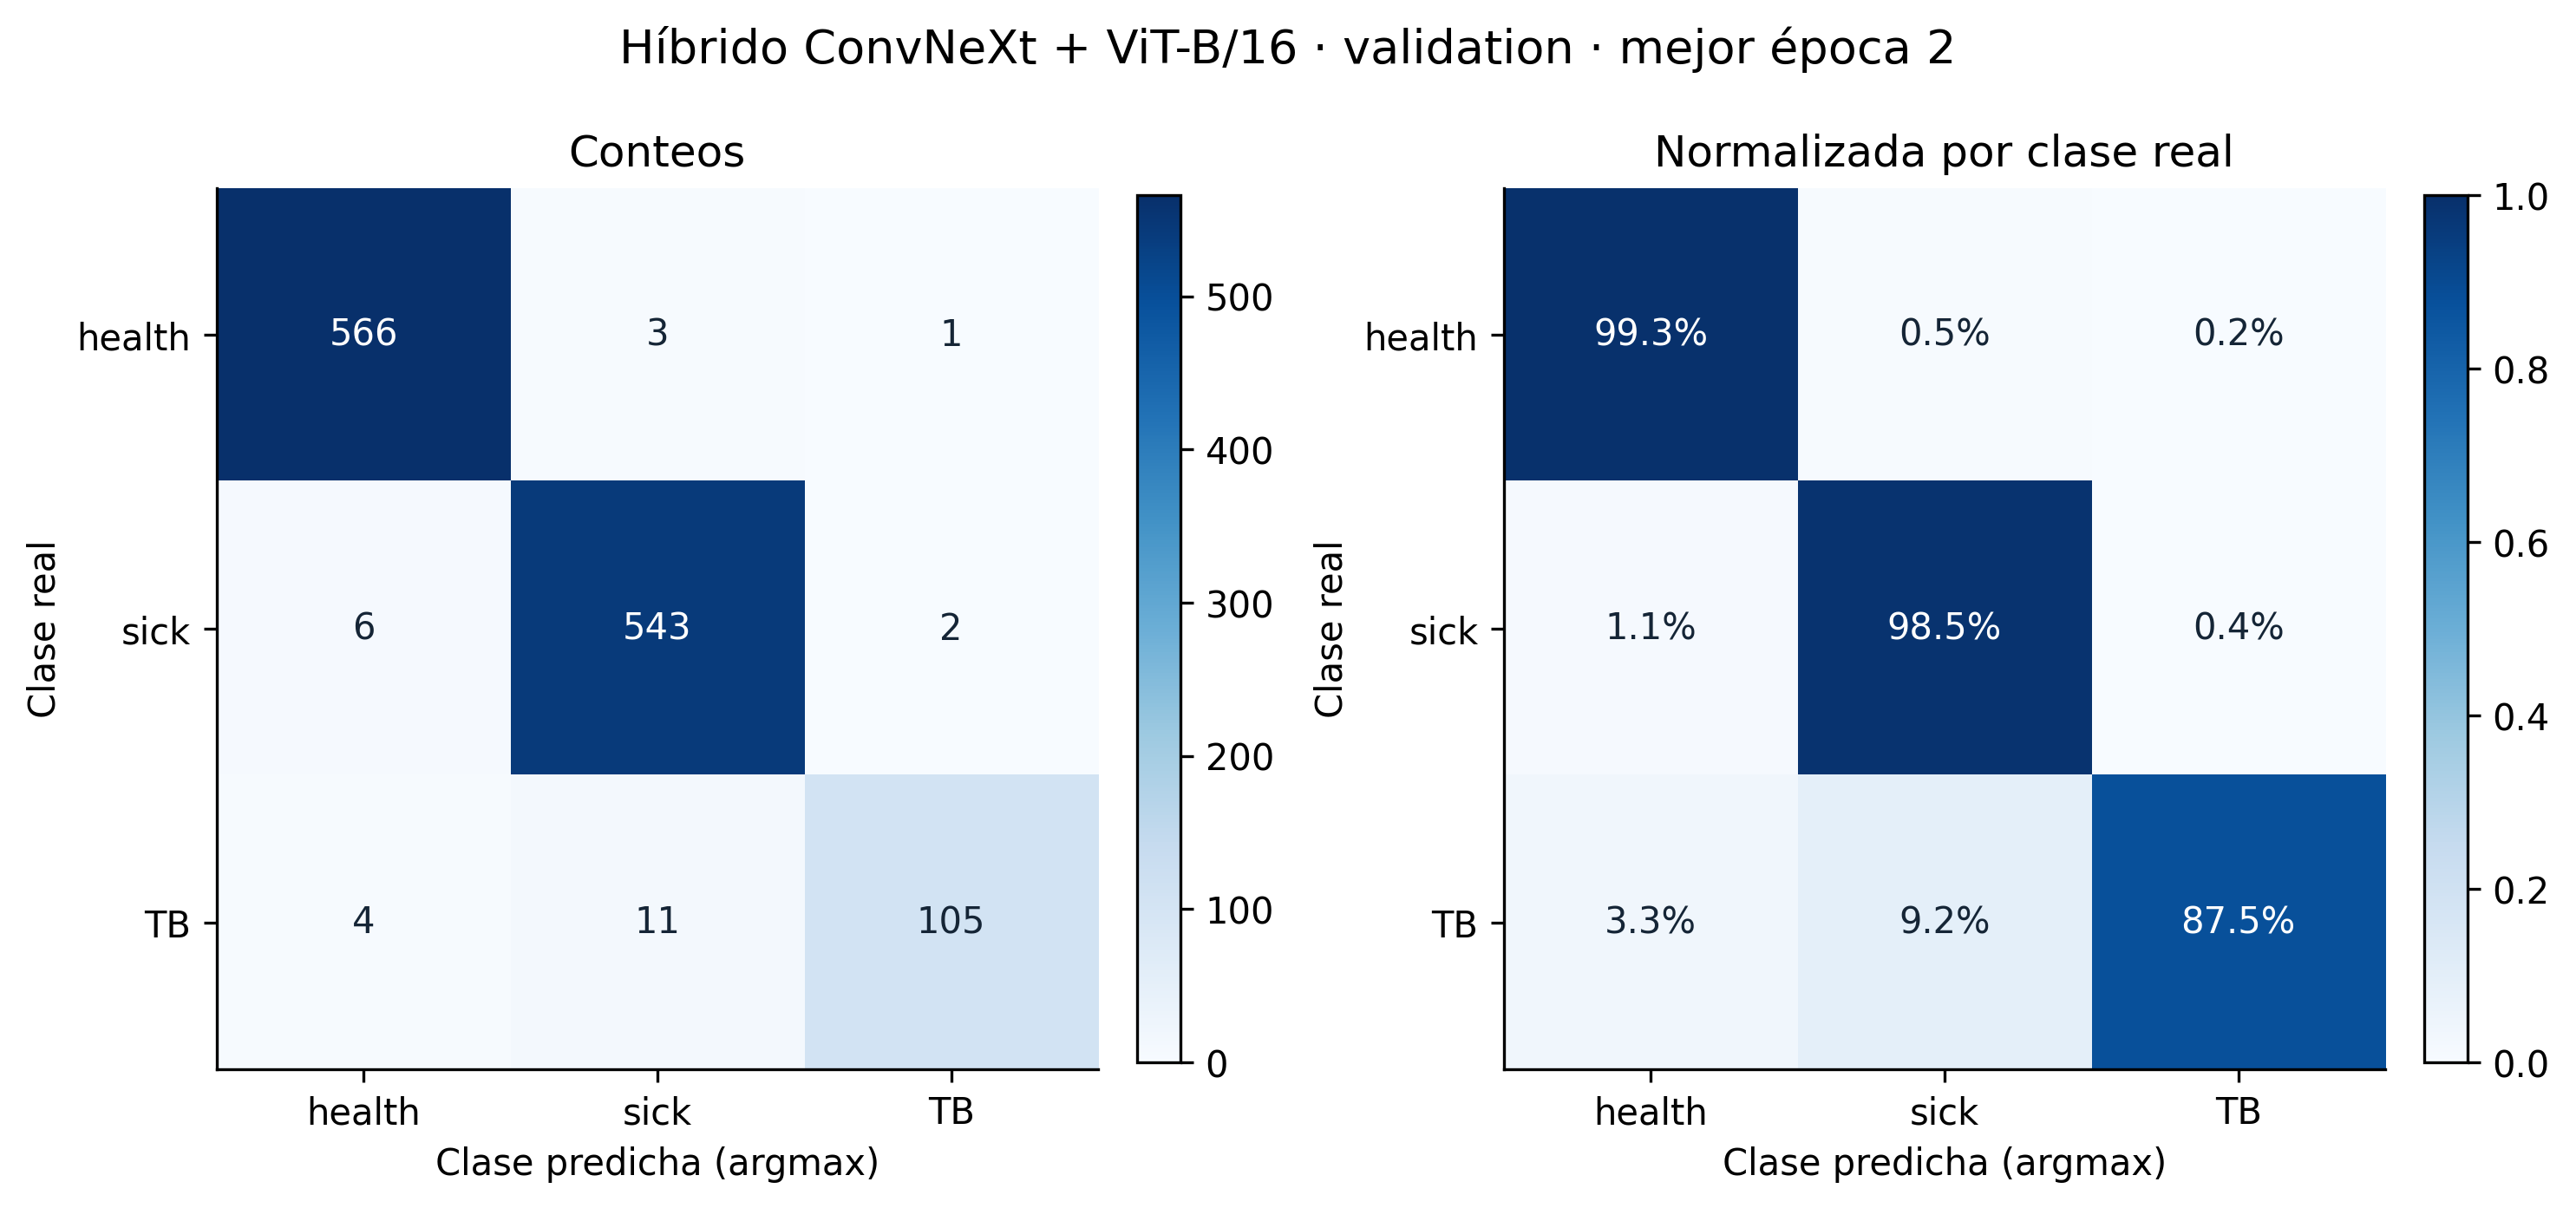

hybrid_convnext_vit_roc.png


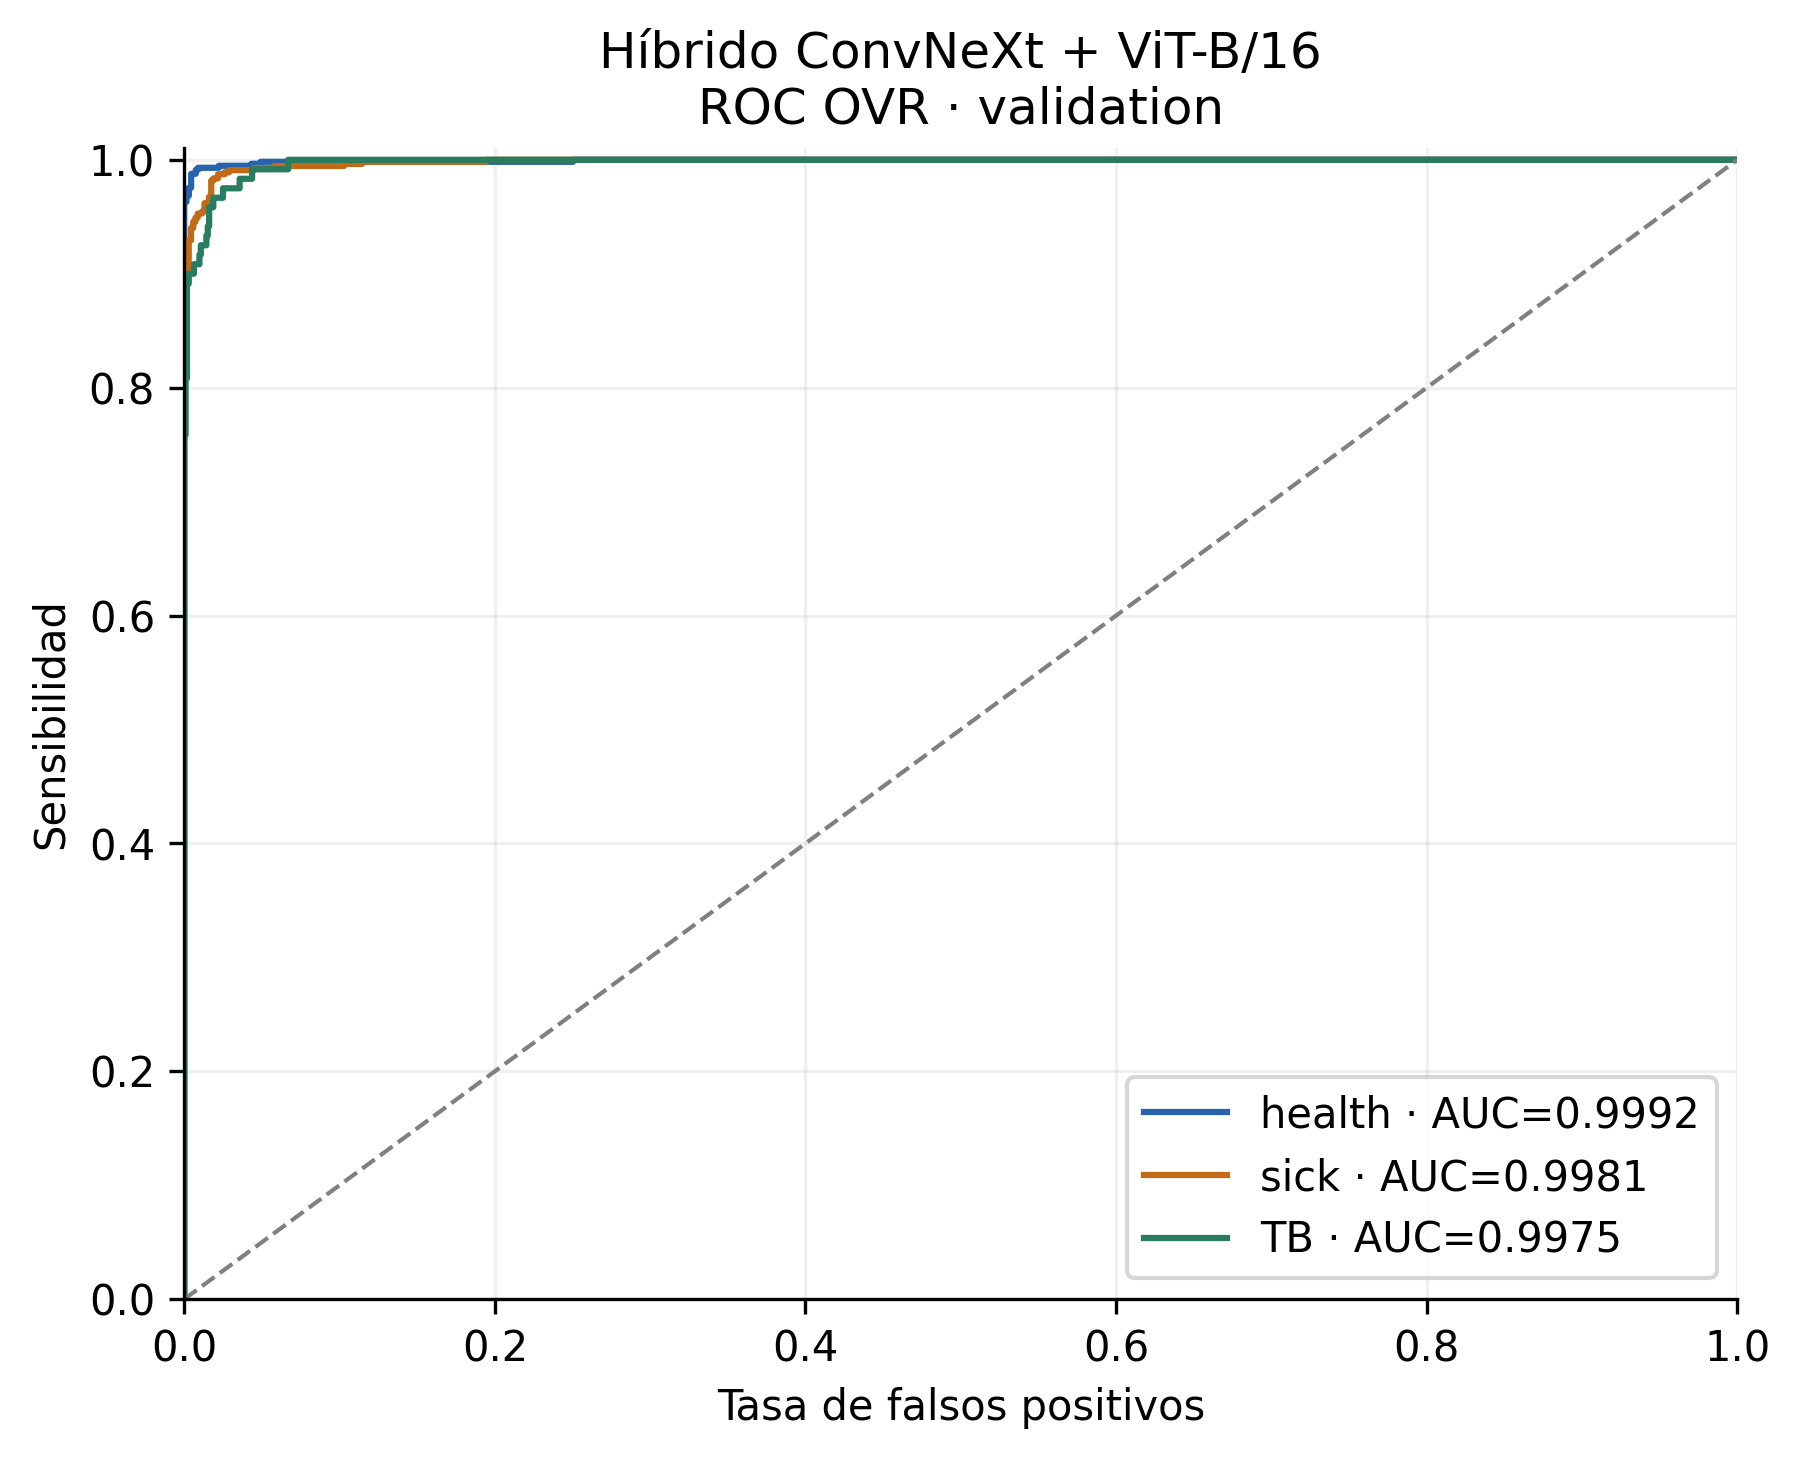

TB_roc_precision_recall.png


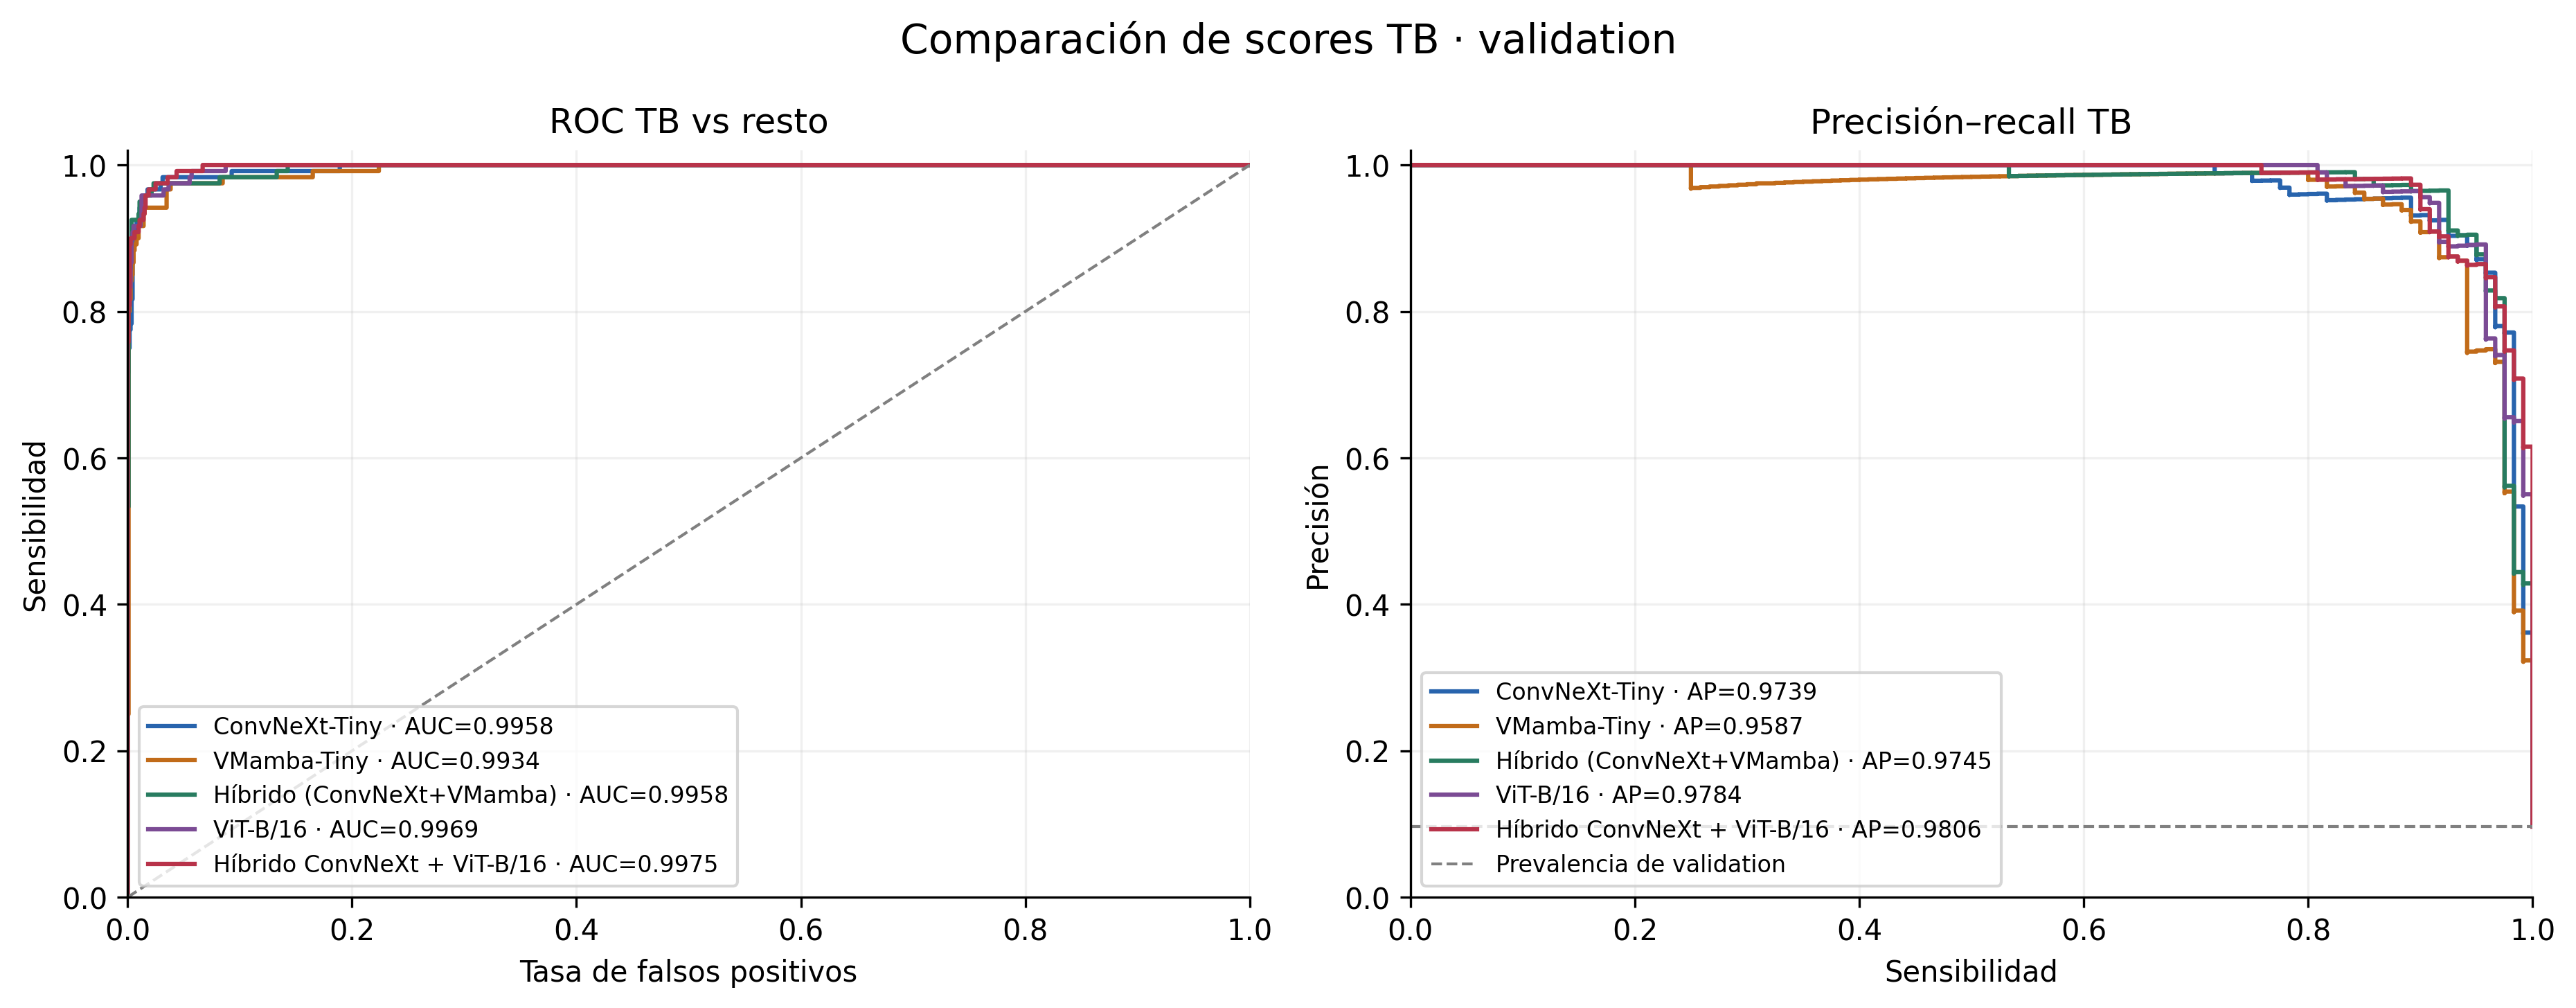

hybrid_convnext_vit_thresholds.png


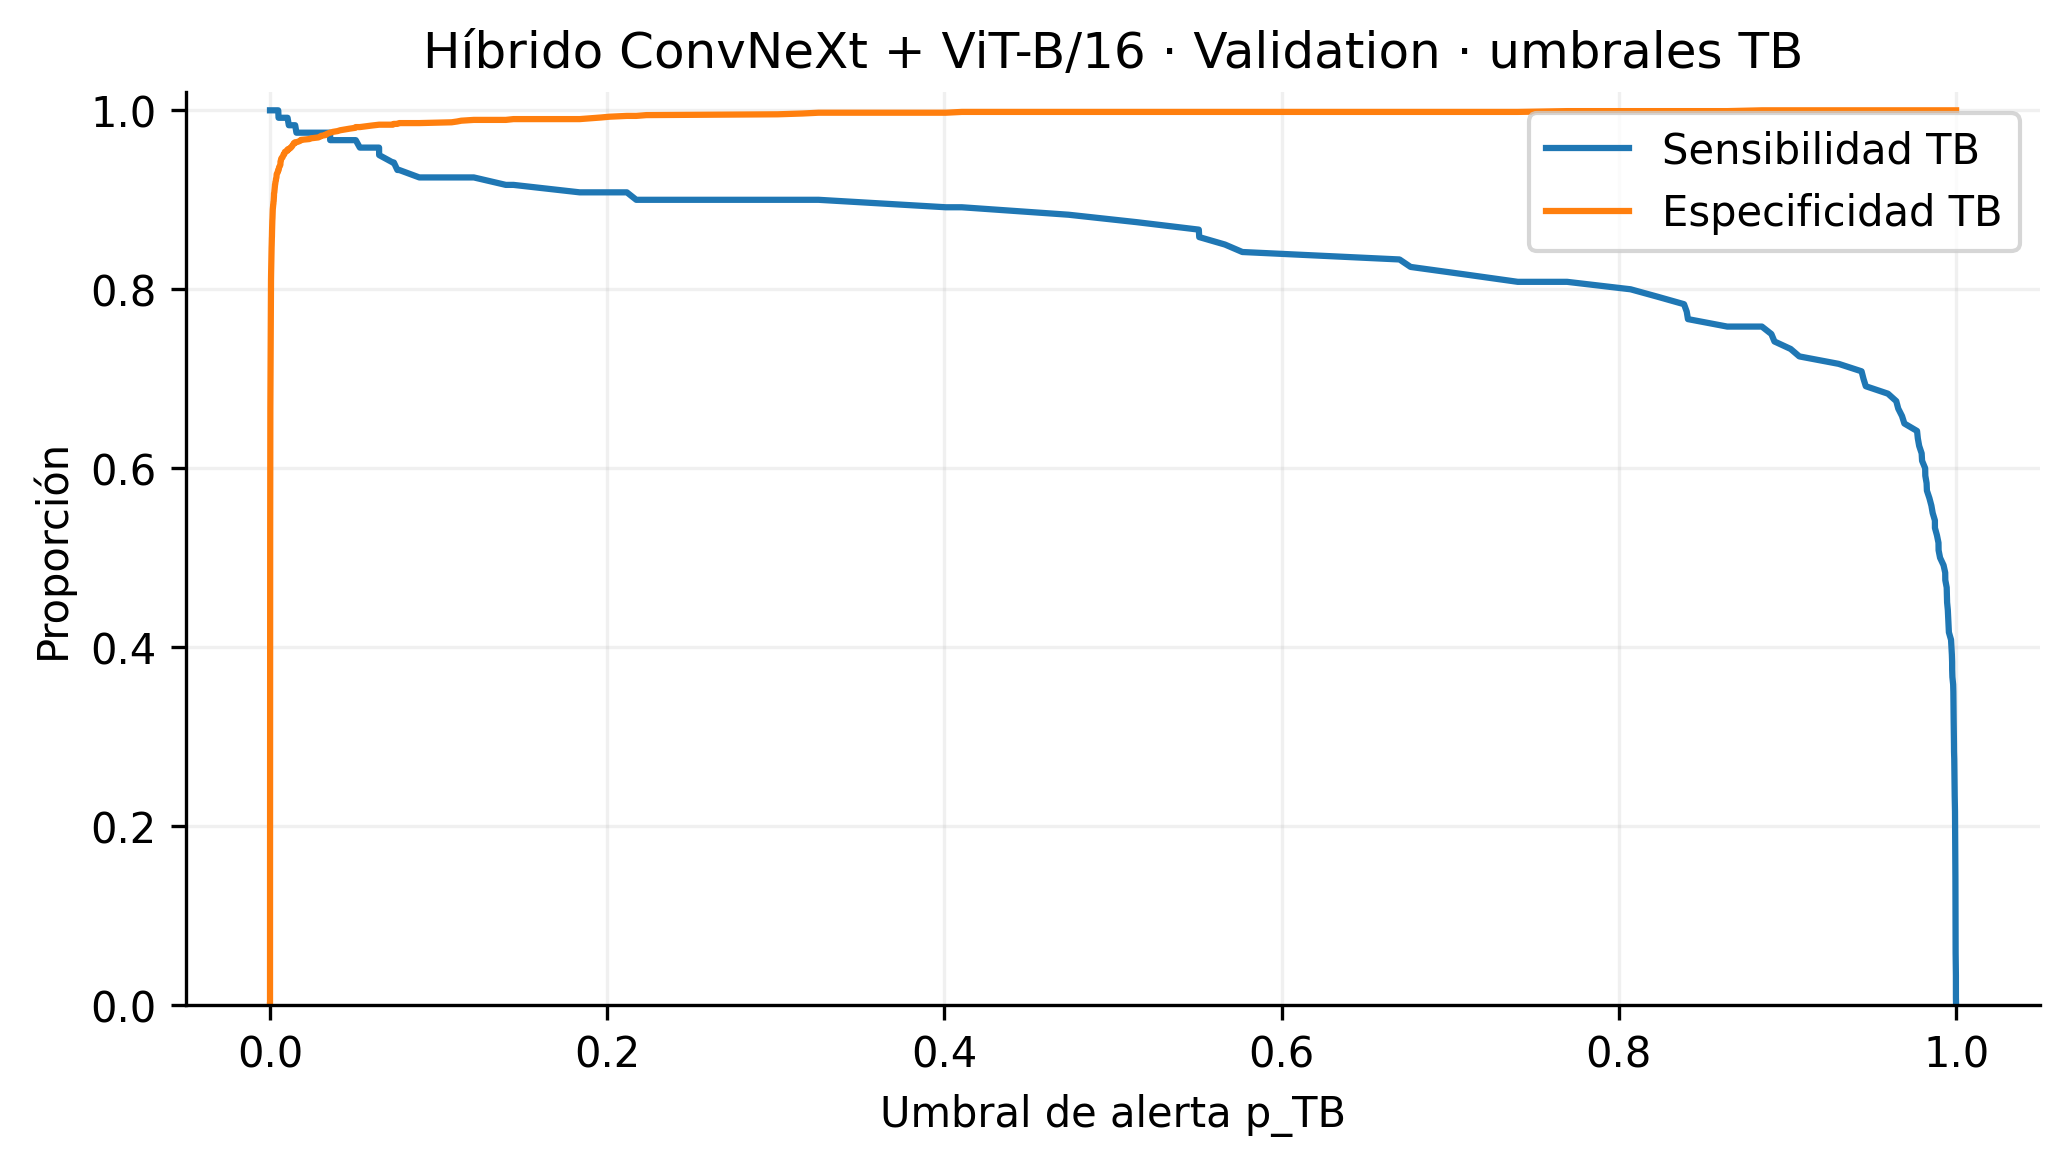

=== PAYLOAD JSON PARA ACTUALIZAR INFORME FASE 5 ===
{
  "schema": "hybrid_vit_phase5_report_payload_v1",
  "scope": "validation_only",
  "test_evaluated": false,
  "external_evaluated": false,
  "candidate_by_macro_f1": "hybrid_cross_attention",
  "comparison_5models": [
    {
      "architecture": "convnext_tiny",
      "display_name": "ConvNeXt-Tiny",
      "short_label": "ConvNeXt",
      "run_id": "phase3_convnext_tiny_20261103T023002Z_4a7e2a",
      "completed_epochs": 12,
      "best_epoch": 11,
      "stop_reason": "epoch_budget",
      "accuracy": 0.9709911361804996,
      "macro_f1": 0.942715557119158,
      "TB_recall": 0.7833333333333333,
      "TB_precision": 0.9690721649484536,
      "TB_specificity": 0.9973238180196253,
      "TB_roc_auc": 0.9957850133809099,
      "TB_recognized": 94,
      "TB_to_health": 4,
      "TB_to_sick": 22,
      "sick_to_TB": 3,
      "health_to_TB": 0,
      "checkpoint_sha256": "33869c4791569f95c262df2987c9a688649aa4f65c92e51e79f8340c1d0c3616

In [5]:
import pandas as pd
from datetime import datetime, timezone
from IPython.display import Image, display
from tbxtrain.protocol import atomic_json
from tbxtrain.hybrid_vit_experiment import export_hybrid_vit_report_outputs

PRIOR_RUNS = {
    'convnext_tiny': 'phase3_convnext_tiny_20261103T023002Z_4a7e2a',
    'vmamba_tiny': 'phase3_vmamba_tiny_20261103T025536Z_4784e4',
    'hybrid_cross_attention': 'phase3_hybrid_cross_attention_20261103T032205Z_71d127',
    'vit_b_16': 'phase3_vit_b_16_20261116T014808Z_2e8a27',
}
OUT_EXPORT = DRIVE_BASE / 'results/hybrid_vit_phase3_export' / (
    HYBRID_VIT_RUN_ID + '_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
)
payload = export_hybrid_vit_report_outputs(
    PROJECT_ROOT, DRIVE_BASE, HYBRID_VIT_RUN_ID, OUT_EXPORT, prior_runs=PRIOR_RUNS,
)
atomic_json(OUT_EXPORT / 'transfer_integrity.json', integrity)

print('=== COMPARACIÓN DE LOS 5 CLASIFICADORES (VALIDATION) ===')
display(pd.DataFrame(payload['comparison_5models'])[
    ['display_name', 'run_id', 'completed_epochs', 'best_epoch', 'stop_reason',
     'accuracy', 'macro_f1', 'TB_recognized', 'TB_recall', 'TB_precision', 'TB_specificity']
])

print('=== HISTORIAL POR ÉPOCA · Híbrido ConvNeXt + ViT-B/16 ===')
display(pd.DataFrame(payload['hybrid_vit_details']['history']))

print('=== TABLA DE UMBRALES TB · Híbrido ConvNeXt + ViT-B/16 (VALIDATION) ===')
display(pd.DataFrame(payload['hybrid_vit_details']['thresholds_grid']))

print('=== CANDIDATO PRINCIPAL POR MACRO-F1 ===', payload['candidate_by_macro_f1'])
display(pd.DataFrame(payload['candidate_thresholds_grid']))

for fig_name in [
    'classifier_comparison.png',
    'hybrid_convnext_vit_training.png',
    'hybrid_convnext_vit_confusion.png',
    'hybrid_convnext_vit_roc.png',
    'TB_roc_precision_recall.png',
    'hybrid_convnext_vit_thresholds.png',
]:
    print(fig_name)
    display(Image(filename=str(OUT_EXPORT / fig_name), width=1000))

print('=== PAYLOAD JSON PARA ACTUALIZAR INFORME FASE 5 ===')
print(json.dumps(payload, indent=2, ensure_ascii=False))
print('Carpeta exportada en Drive:', OUT_EXPORT)
print('Guarde este notebook ejecutado con Ctrl+S.')